# Задача 2. Создание источника фотонов

**Проект:** моделирование жидкосцинтилляционного детектора

В ноутбуке реализован класс `Source`, который для события с энергией \(E\) генерирует начальные направления сцинтилляционных фотонов.

## Модель и допущения

Из условия задачи:
- свет испускается **изотропно**;
- средний выход фотонов линейно пропорционален энергии события:
  \[
  \overline{N_\gamma}=Y E,\qquad
  Y=10\,000\ \text{фотонов/МэВ}.
  \]

Для изотропного направления азимутальный угол \(\varphi\) равномерно распределён на \([0,2\pi)\), а косинус полярного угла \(\mu=\cos\theta\) — на \([-1,1]\). Важно: равномерно разыгрывать сам угол \(\theta\) нельзя — это не даст изотропного распределения на сфере.

По умолчанию число фотонов берётся равным округлённому \(YE\), то есть строго следует заданному линейному закону. Дополнительно предусмотрен режим `poisson=True`: число фотонов разыгрывается из распределения Пуассона со средним \(YE\). Это необязательное статистическое расширение модели, а не дополнительное требование условия.

Класс возвращает единичные векторы направлений фотонов в декартовых координатах. Координаты точки рождения фотонов и распространение в веществе в рамках этой задачи не моделируются.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from typing import Optional

YIELD_PER_MEV = 10_000


## Реализация класса `Source`

Интерфейс минимален: конструктор задаёт световыход, а `generate_directions` принимает энергию события и генератор случайных чисел. Использование `numpy.random.Generator` позволяет воспроизводить результаты по seed и не затрагивать глобальное состояние RNG.

In [8]:
class Source:
    """Изотропный источник сцинтилляционных фотонов.

    Parameters
    ----------
    Y : float, default=10_000
        Световыход, фотонов/МэВ.

    Notes
    -----
    Возвращаемые направления — единичные векторы (x, y, z).
    При poisson=False число фотонов равно round(Y * E).
    При poisson=True число фотонов имеет распределение Пуассона
    со средним Y * E.
    """

    def __init__(self, Y: float = YIELD_PER_MEV) -> None:
        if not np.isfinite(Y) or Y <= 0:
            raise ValueError("Y должен быть конечным положительным числом.")
        self.Y = float(Y)

    def photon_count(
        self,
        E: float,
        rng: Optional[np.random.Generator] = None,
        poisson: bool = False,
    ) -> int:
        """Определить число фотонов для энергии события E (МэВ)."""
        if not np.isfinite(E) or E < 0:
            raise ValueError("Энергия E должна быть конечной и неотрицательной.")

        mean_count = self.Y * float(E)

        if poisson:
            rng = np.random.default_rng() if rng is None else rng
            return int(rng.poisson(mean_count))

        return int(np.rint(mean_count))

    def generate_directions(
        self,
        E: float,
        rng: Optional[np.random.Generator] = None,
        poisson: bool = False,
    ) -> np.ndarray:
        """Сгенерировать изотропные направления фотонов для события E.

        Returns
        -------
        numpy.ndarray
            Массив формы (N_gamma, 3); каждая строка — единичный
            вектор направления фотона.
        """
        rng = np.random.default_rng() if rng is None else rng
        n_photons = self.photon_count(E, rng=rng, poisson=poisson)

        # Для равномерного распределения на сфере:
        # phi ~ U[0, 2*pi), mu = cos(theta) ~ U[-1, 1].
        phi = rng.uniform(0.0, 2.0 * np.pi, size=n_photons)
        mu = rng.uniform(-1.0, 1.0, size=n_photons)
        transverse = np.sqrt(np.maximum(0.0, 1.0 - mu**2))

        directions = np.column_stack((
            transverse * np.cos(phi),
            transverse * np.sin(phi),
            mu,
        ))
        return directions


## Проверка работы класса

Для события с энергией 1 МэВ ожидается 10 000 фотонов. Проверим размер массива, единичную длину каждого вектора и воспроизводимость генерации при фиксированном seed.

In [9]:
source = Source()
rng = np.random.default_rng(seed=42)

energy_mev = 1.0
directions = source.generate_directions(energy_mev, rng=rng)

print(f"Энергия события: {energy_mev:.3f} МэВ")
print(f"Световыход:      {source.Y:.0f} фотонов/МэВ")
print(f"Число фотонов:   {len(directions):,}")
print(f"Форма массива:   {directions.shape}")
print(f"Средняя длина вектора: {np.linalg.norm(directions, axis=1).mean():.12f}")

assert directions.shape == (10_000, 3)
assert np.allclose(np.linalg.norm(directions, axis=1), 1.0)


Энергия события: 1.000 МэВ
Световыход:      10000 фотонов/МэВ
Число фотонов:   10,000
Форма массива:   (10000, 3)
Средняя длина вектора: 1.000000000000


## Визуальная проверка изотропности

Для изотропного источника величины \(\cos\theta\) и \(\varphi\) должны иметь равномерные распределения на своих интервалах. На графиках ниже показаны гистограммы и ожидаемая плотность.

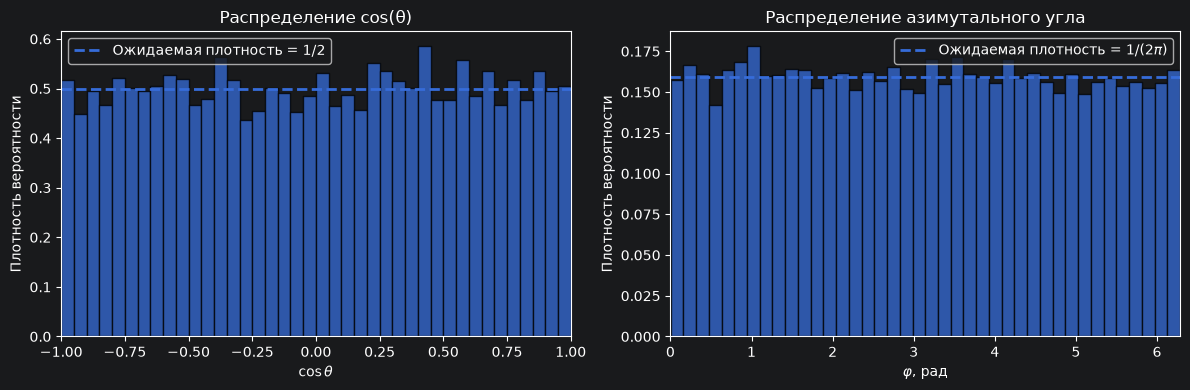

In [10]:
mu = directions[:, 2]  # cos(theta)
phi = np.mod(np.arctan2(directions[:, 1], directions[:, 0]), 2 * np.pi)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(mu, bins=40, density=True, alpha=0.75, edgecolor="black")
axes[0].axhline(0.5, linestyle="--", linewidth=2, label="Ожидаемая плотность = 1/2")
axes[0].set(
    xlabel=r"$\cos\theta$",
    ylabel="Плотность вероятности",
    title="Распределение cos(θ)",
    xlim=(-1, 1),
)
axes[0].legend()

axes[1].hist(phi, bins=40, density=True, alpha=0.75, edgecolor="black")
axes[1].axhline(1 / (2 * np.pi), linestyle="--", linewidth=2,
                label=r"Ожидаемая плотность = $1/(2\pi)$")
axes[1].set(
    xlabel=r"$\varphi$, рад",
    ylabel="Плотность вероятности",
    title="Распределение азимутального угла",
    xlim=(0, 2 * np.pi),
)
axes[1].legend()

plt.tight_layout()
plt.show()


## Проверка линейного закона световыхода

Проверим число фотонов для нескольких энергий. В детерминированном режиме результат должен соответствовать \(N_\gamma=YE\) с точностью до округления до целого числа фотонов.

E =  0.1 МэВ  ->  N_gamma =   1,000
E =  0.5 МэВ  ->  N_gamma =   5,000
E =  1.0 МэВ  ->  N_gamma =  10,000
E =  2.0 МэВ  ->  N_gamma =  20,000
E =  5.0 МэВ  ->  N_gamma =  50,000


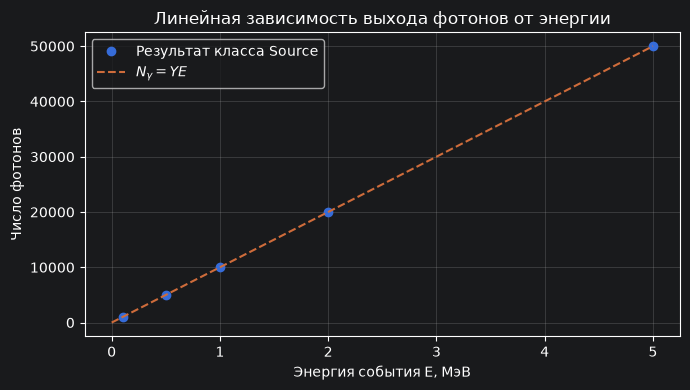

In [11]:
energies = np.array([0.1, 0.5, 1.0, 2.0, 5.0])
counts = np.array([source.photon_count(E) for E in energies])

for E, count in zip(energies, counts):
    print(f"E = {E:4.1f} МэВ  ->  N_gamma = {count:>7,d}")

plt.figure(figsize=(7, 4))
plt.plot(energies, counts, "o", label="Результат класса Source")
energy_line = np.linspace(0, energies.max(), 200)
plt.plot(energy_line, source.Y * energy_line, "--", label=r"$N_\gamma = YE$")
plt.xlabel("Энергия события E, МэВ")
plt.ylabel("Число фотонов")
plt.title("Линейная зависимость выхода фотонов от энергии")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Необязательное расширение: флуктуации числа фотонов

Если требуется учитывать статистические флуктуации числа испущенных фотонов, можно включить `poisson=True`. Тогда \(N_\gamma\sim\mathrm{Poisson}(YE)\), поэтому математическое ожидание равно \(YE\), а дисперсия — также \(YE\).

Теоретическое среднее: 10000.0
Выборочное среднее:    10001.60
Теоретическая sigma:   100.00
Выборочная sigma:      101.84


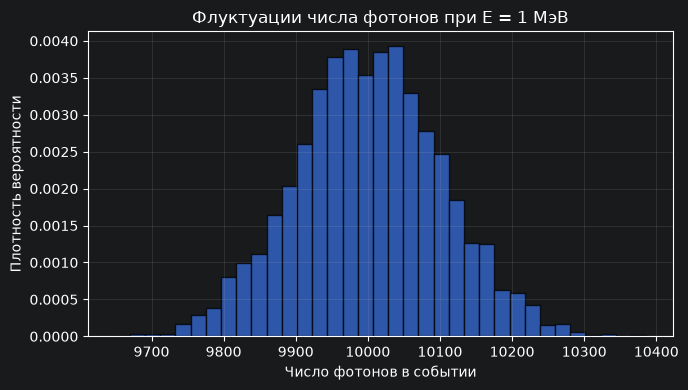

In [12]:
rng = np.random.default_rng(seed=7)
n_trials = 5_000
E_test = 1.0

poisson_counts = np.array([
    source.photon_count(E_test, rng=rng, poisson=True)
    for _ in range(n_trials)
])

expected = source.Y * E_test
print(f"Теоретическое среднее: {expected:.1f}")
print(f"Выборочное среднее:    {poisson_counts.mean():.2f}")
print(f"Теоретическая sigma:   {np.sqrt(expected):.2f}")
print(f"Выборочная sigma:      {poisson_counts.std(ddof=1):.2f}")

plt.figure(figsize=(7, 4))
plt.hist(poisson_counts, bins=35, density=True, edgecolor="black", alpha=0.75)
plt.xlabel("Число фотонов в событии")
plt.ylabel("Плотность вероятности")
plt.title(f"Флуктуации числа фотонов при E = {E_test:g} МэВ")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## Итог

Реализован класс `Source` со световыходом по умолчанию
\(Y=10^4\) фотонов/МэВ. Для заданной энергии он:

1. вычисляет число фотонов согласно линейному закону световыхода;
2. генерирует для каждого фотона изотропное направление;
3. возвращает массив единичных векторов `(N_gamma, 3)`.

Изотропность обеспечивается равномерной генерацией азимута и косинуса полярного угла. Для воспроизводимости расчёта следует передавать генератор `np.random.default_rng(seed)`. Режим пуассоновских флуктуаций оставлен опциональным, поскольку условие задачи задаёт линейный выход, но не требует явно моделировать его статистические флуктуации.